# Аналіз замовлень маркетплейсу Olist

**Мета.** Я проаналізував близько 100 тисяч замовлень бразильського маркетплейсу Olist за 2016-2018 роки. Хотів зрозуміти, як росте бізнес, які категорії й штати приносять найбільше, і головне: **як затримка доставки впливає на оцінки клієнтів**.

**Дані.** Спочатку я підготував у PostgreSQL (папка `sql/`) дві таблиці:
- `orders_full`: один рядок = одне замовлення;
- `order_items_full`: один рядок = одна позиція замовлення (з категорією товару).

Поля `delivery_days`, `delay_days`, `is_late`, `is_valid_order` я розрахував у SQL.

**Правила, яких я дотримувався:**
1. Валідне замовлення: не скасоване, не `unavailable` і має хоча б один товар.
2. Виручка = ціна товарів без доставки.
3. Динаміку дивлюсь за 2017-01 ... 2018-08, бо інші місяці неповні.
4. Доставку аналізую лише для доставлених замовлень з датою доставки.
5. Оцінка замовлення = округлене середнє всіх його відгуків.

## 1. Завантаження даних

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (10, 4)
pd.set_option('display.float_format', '{:,.2f}'.format)

In [38]:
orders_cols = [
    'order_id', 'customer_unique_id', 'customer_state', 'order_status',
    'purchased_at', 'delivered_at', 'estimated_at',
    'items_count', 'items_value', 'freight_value', 'payment_value',
    'review_score', 'is_valid_order', 'delivery_days', 'delay_days',
    'purchase_month', 'is_late', 'delay_group',
]
items_cols = [
    'order_id', 'order_item_id', 'product_id', 'seller_id', 'seller_state',
    'category', 'price', 'freight_value', 'customer_state', 'order_status',
    'purchased_at', 'purchase_month', 'is_valid_order', 'review_score',
    'delay_days', 'is_late',
]

# Файли вивантажені з PostgreSQL: роздільник - табуляція, заголовка немає,
# пропуски записані як \N
orders = pd.read_csv(
    '../data/processed/orders_full.csv',
    sep='\t', header=None, names=orders_cols, na_values=['\\N'],
    parse_dates=['purchased_at', 'delivered_at', 'estimated_at'],
)
items = pd.read_csv(
    '../data/processed/order_items_full.csv',
    sep='\t', header=None, names=items_cols, na_values=['\\N'],
)

# Місяць покупки для групування по місяцях
orders['month'] = orders['purchased_at'].dt.to_period('M').dt.to_timestamp()

orders.info()
orders.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            99441 non-null  object        
 1   customer_unique_id  99441 non-null  object        
 2   customer_state      99441 non-null  object        
 3   order_status        99441 non-null  object        
 4   purchased_at        99441 non-null  datetime64[ns]
 5   delivered_at        96476 non-null  datetime64[ns]
 6   estimated_at        99441 non-null  datetime64[ns]
 7   items_count         98666 non-null  float64       
 8   items_value         98666 non-null  float64       
 9   freight_value       98666 non-null  float64       
 10  payment_value       99440 non-null  float64       
 11  review_score        98673 non-null  float64       
 12  is_valid_order      99441 non-null  int64         
 13  delivery_days       96470 non-null  float64   

,order_id,customer_unique_id,customer_state,order_status,purchased_at,delivered_at,estimated_at,items_count,items_value,freight_value,payment_value,review_score,is_valid_order,delivery_days,delay_days,purchase_month,is_late,delay_group,month
0,00018f77f2f0320c557190d7a144bdd3,eb28e67c4c0b83846050ddfb8a35d051,SP,delivered,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15,1.00,239.90,19.93,259.83,4.00,1,16.00,-3.00,2017-04-01,0.00,1. On time or early,2017-04-01
1,000229ec398224ef6ca0657da4fc703e,3818d81c6709e39d06b2738a8d3a2474,MG,delivered,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05,1.00,199.00,17.87,216.87,5.00,1,8.00,-14.00,2018-01-01,0.00,1. On time or early,2018-01-01
2,00024acbcdf0a6daa1e931b038114c75,af861d436cfc08b2c2ddefd0ba074622,SP,delivered,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20,1.00,12.99,12.79,25.78,4.00,1,6.00,-6.00,2018-08-01,0.00,1. On time or early,2018-08-01


## 2. Якість даних

In [39]:
print('Рядків:', len(orders))
print('Унікальних order_id:', orders['order_id'].nunique())
print()
print('Пропуски:')
missing = orders.isna().sum()
print(missing[missing > 0])
print()
print(orders['order_status'].value_counts())

Рядків: 99441
Унікальних order_id: 99441

Пропуски:
delivered_at     2965
items_count       775
items_value       775
freight_value     775
payment_value       1
review_score      768
delivery_days    2971
delay_days       2971
is_late          2971
delay_group      2971
dtype: int64

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


**Мій висновок.** Дублікатів немає: кожне з 99 441 замовлень зустрічається один раз. Пропуски я перевірив і вони мають пояснення:
- 775 замовлень без товарів: це переважно скасовані та `unavailable`;
- 2 965 замовлень без дати доставки: вони ще в дорозі або скасовані;
- 768 замовлень без відгуку: клієнт просто не залишив оцінку.

Це не помилки в даних, тож я нічого не видаляю, а далі фільтрую за правилами вище. 97% замовлень (96 478) доставлені, скасованих лише 625.

In [40]:
valid = orders[orders['is_valid_order'] == 1]
print('Валідних замовлень:', len(valid), 'з', len(orders))
print('Частка, %:', round(len(valid) / len(orders) * 100, 1))

Валідних замовлень: 98199 з 99441
Частка, %: 98.8


## 3. Замовлення та виручка по місяцях

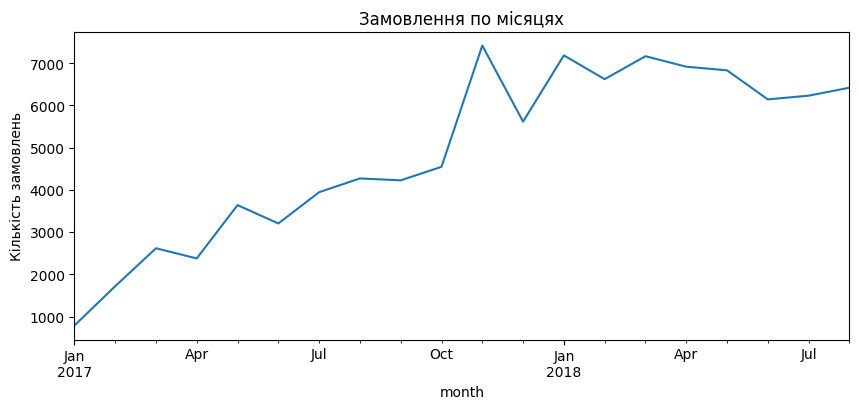

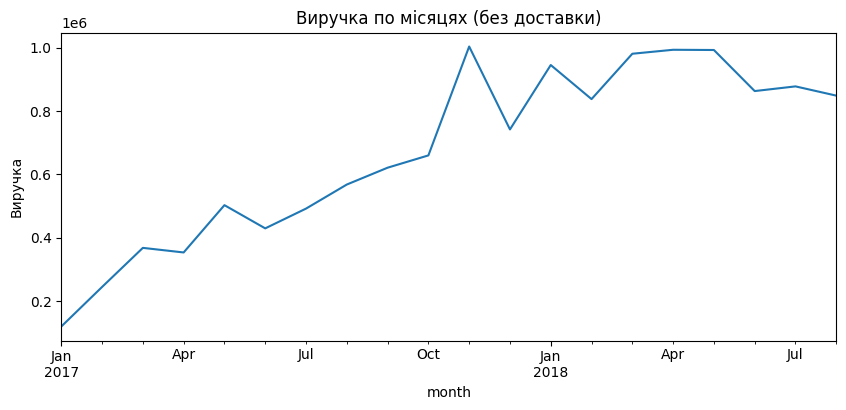

Місяць з найбільшою кількістю замовлень: 2017-11
Зростання замовлень (останній місяць / перший): 8.2
Зростання виручки (останній місяць / перший): 7.1


,orders,revenue,avg_order_value
month,,,
2017-01-01,787,"120,098.00",153.00
2017-02-01,1718,"244,959.00",143.00
2017-03-01,2617,"368,341.00",141.00
2017-04-01,2377,"353,843.00",149.00
2017-05-01,3640,"503,159.00",138.00
2017-06-01,3205,"429,917.00",134.00
2017-07-01,3946,"492,287.00",125.00
2017-08-01,4272,"568,246.00",133.00
2017-09-01,4227,"621,416.00",147.00


In [41]:
period = valid[(valid['purchased_at'] >= '2017-01-01') & (valid['purchased_at'] < '2018-09-01')]

monthly = period.groupby('month').agg(
    orders=('order_id', 'count'),
    revenue=('items_value', 'sum'),
)
monthly['avg_order_value'] = monthly['revenue'] / monthly['orders']

monthly['orders'].plot(title='Замовлення по місяцях')
plt.ylabel('Кількість замовлень')
plt.show()

monthly['revenue'].plot(title='Виручка по місяцях (без доставки)')
plt.ylabel('Виручка')
plt.show()

print('Місяць з найбільшою кількістю замовлень:', monthly['orders'].idxmax().strftime('%Y-%m'))
print('Зростання замовлень (останній місяць / перший):', round(monthly['orders'].iloc[-1] / monthly['orders'].iloc[0], 1))
print('Зростання виручки (останній місяць / перший):', round(monthly['revenue'].iloc[-1] / monthly['revenue'].iloc[0], 1))
monthly.round(0)

**Мій висновок.**
- Бізнес швидко ріс: з 787 замовлень у січні 2017 до серпня 2018 кількість замовлень на місяць зросла приблизно у **8 разів**, а виручка у **7 разів**.
- Середній чек за цей час знизився на 13%. Тобто зростання дала кількість замовлень, а не дорожчі покупки.
- Різкий пік у листопаді 2017: 7 421 замовлення, на 63% більше за медіану інших місяців. Найімовірніше, це Black Friday.

## 4. Категорії за виручкою

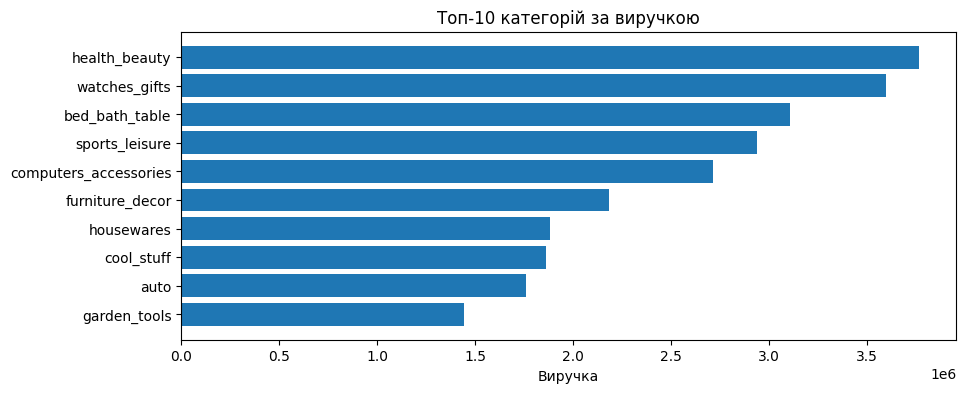

Частка топ-3 категорій, %: 26.1
Частка топ-10 категорій, %: 62.9


,items_sold,revenue,revenue_pct
category,,,
health_beauty,28902,"3,767,085.40",9.40
watches_gifts,17910,"3,594,555.60",9.00
bed_bath_table,33291,"3,107,892.20",7.70
sports_leisure,25770,"2,939,222.80",7.30
computers_accessories,23343,"2,712,966.10",6.80
furniture_decor,24894,"2,182,395.20",5.40
housewares,20745,"1,880,477.40",4.70
cool_stuff,11337,"1,862,311.50",4.60
auto,12612,"1,759,757.20",4.40


In [42]:
valid_items = items[items['is_valid_order'] == 1]

categories = valid_items.groupby('category').agg(
    items_sold=('order_id', 'count'),
    revenue=('price', 'sum'),
).sort_values('revenue', ascending=False)
categories['revenue_pct'] = categories['revenue'] / categories['revenue'].sum() * 100

top10 = categories.head(10)

plot_data = top10['revenue'].sort_values()
plt.barh(plot_data.index, plot_data.values)
plt.title('Топ-10 категорій за виручкою')
plt.xlabel('Виручка')
plt.show()

print('Частка топ-3 категорій, %:', round(top10['revenue_pct'].head(3).sum(), 1))
print('Частка топ-10 категорій, %:', round(top10['revenue_pct'].sum(), 1))
top10.round(1)

**Мій висновок.**
- Найбільше виручки дають `health_beauty` (9,4%), `watches_gifts` (9,0%) і `bed_bath_table` (7,7%). Разом вони складають 26,1%, а топ-10 категорій 62,9%.
- Жодна категорія не домінує, тож бізнес не залежить від однієї категорії.
- Цікаво, що `watches_gifts` на другому місці за виручкою, хоча продано майже вдвічі менше товарів, ніж у `bed_bath_table` (17 910 проти 33 291). Це дорожчі товари.

## 5. Доставка

count   96,470.00
mean        12.50
std          9.56
min          0.00
25%          7.00
50%         10.00
75%         16.00
max        210.00
Name: delivery_days, dtype: float64

Середня різниця з обіцяною датою, днів (мінус = раніше): -11.9
Частка запізнених замовлень, %: 6.8
Доставка довша за 60 днів: 298


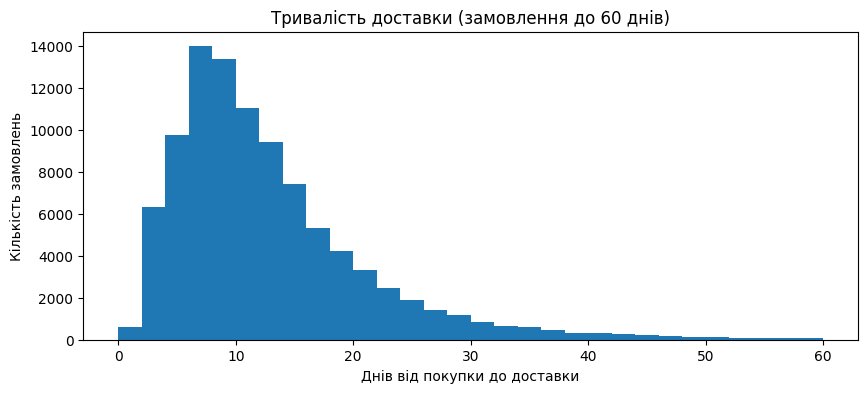

In [43]:
delivered = orders[orders['delivery_days'].notna()].copy()

print(delivered['delivery_days'].describe())
print()
print('Середня різниця з обіцяною датою, днів (мінус = раніше):', round(delivered['delay_days'].mean(), 1))
print('Частка запізнених замовлень, %:', round(delivered['is_late'].mean() * 100, 1))
print('Доставка довша за 60 днів:', (delivered['delivery_days'] > 60).sum())

short = delivered[delivered['delivery_days'] <= 60]
plt.hist(short['delivery_days'], bins=30)
plt.title('Тривалість доставки (замовлення до 60 днів)')
plt.xlabel('Днів від покупки до доставки')
plt.ylabel('Кількість замовлень')
plt.show()

**Мій висновок.**
- Середня доставка 12,5 дня, медіана 10 днів. 75% замовлень доставлено за 16 днів або швидше.
- У середньому товар приходить на 11,9 дня **раніше** обіцяної дати, тому запізнюється лише **6,8%** замовлень.
- 298 замовлень доставляли понад 60 днів (максимум 210). Це рідкісні викиди, на графіку я їх не показую, але в даних залишаю.

## 6. Затримка і оцінка клієнта

             count  mean
delay_group             
Вчасно       89443  4.29
1-3 дні       1852  3.29
4-7 днів      1748  2.11
7+ днів       2781  1.70


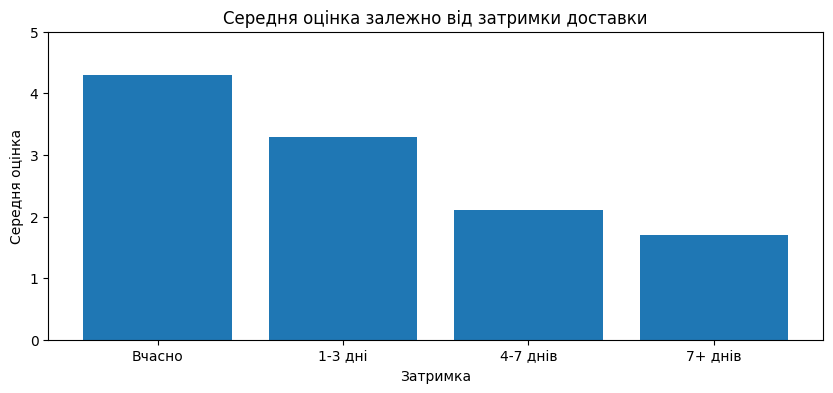

In [44]:
rated = delivered[delivered['review_score'].notna()].copy()

labels = {
    '1. On time or early': 'Вчасно',
    '2. 1-3 days late': '1-3 дні',
    '3. 4-7 days late': '4-7 днів',
    '4. More than 7 days late': '7+ днів',
}
by_group = rated.groupby('delay_group')['review_score'].agg(['count', 'mean'])
by_group = by_group.rename(index=labels)
print(by_group)

plt.bar(by_group.index, by_group['mean'])
plt.title('Середня оцінка залежно від затримки доставки')
plt.xlabel('Затримка')
plt.ylabel('Середня оцінка')
plt.ylim(0, 5)
plt.show()

In [45]:
rated['late_label'] = rated['is_late'].map({0: 'Вчасно', 1: 'Із запізненням'})
rated['bad_review'] = rated['review_score'] <= 2

print('Середня оцінка:')
print(rated.groupby('late_label')['review_score'].mean().round(2))
print()
print('Частка оцінок 1-2, %:')
print((rated.groupby('late_label')['bad_review'].mean() * 100).round(1))

Середня оцінка:
late_label
Із запізненням   2.27
Вчасно           4.29
Name: review_score, dtype: float64

Частка оцінок 1-2, %:
late_label
Із запізненням   62.40
Вчасно            9.20
Name: bad_review, dtype: float64


**Мій висновок (головний інсайт проєкту).**
- Чим довша затримка, тим нижча оцінка: вчасно **4,29**, 1-3 дні **3,29**, 4-7 днів **2,11**, понад 7 днів **1,70**.
- Замовлення із запізненням у середньому отримують **2,27** проти 4,29 вчасно, різниця понад 2 бали.
- Поганих оцінок (1-2) при доставці вчасно лише **9,2%**, а при запізненні **62,4%**.
- Отже, навіть затримка на 1-3 дні сильно псує враження клієнта. Для бізнесу важливо не стільки доставляти швидше, скільки **не порушувати обіцяну дату**.

**Обмеження.** Це кореляція, а не доказ причини. Оцінку можуть знижувати й інші чинники (якість товару), а клієнти із запізненням частіше пишуть відгук, тому частка поганих оцінок може бути завищена.

## 7. Географія: замовлення та запізнення за штатами

In [46]:
state_share = valid['customer_state'].value_counts(normalize=True) * 100
print('Топ-3 штати за кількістю замовлень, %:')
print(state_share.head(3).round(1))
print('Разом, %:', round(state_share.head(3).sum(), 1))

Топ-3 штати за кількістю замовлень, %:
customer_state
SP   41.90
RJ   12.90
MG   11.70
Name: proportion, dtype: float64
Разом, %: 66.5


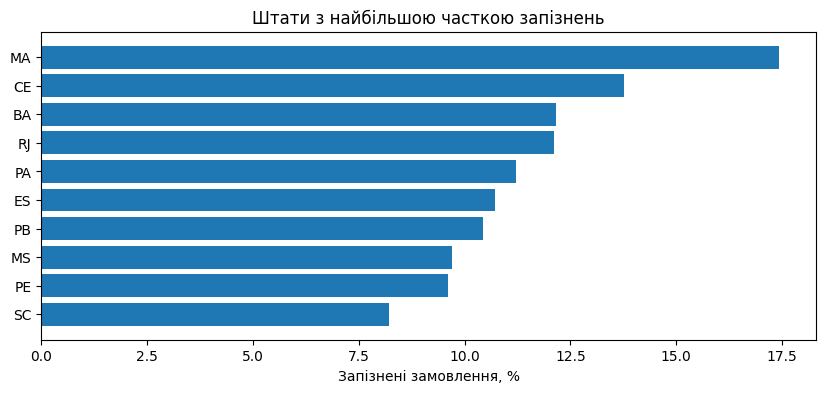

,delivered_orders,late_orders,late_pct
customer_state,,,
MA,717,125.00,17.40
CE,1279,176.00,13.80
BA,3256,396.00,12.20
RJ,12350,"1,495.00",12.10
PA,946,106.00,11.20
ES,1995,214.00,10.70
PB,517,54.00,10.40
MS,701,68.00,9.70
PE,1593,153.00,9.60


In [47]:
states = delivered.groupby('customer_state').agg(
    delivered_orders=('order_id', 'count'),
    late_orders=('is_late', 'sum'),
    late_pct=('is_late', 'mean'),
)
states['late_pct'] = states['late_pct'] * 100

# беремо штати, де є хоча б 500 доставлених замовлень
top_late = states[states['delivered_orders'] >= 500].sort_values('late_pct', ascending=False).head(10)

plot_data = top_late['late_pct'].sort_values()
plt.barh(plot_data.index, plot_data.values)
plt.title('Штати з найбільшою часткою запізнень')
plt.xlabel('Запізнені замовлення, %')
plt.show()

top_late.round(1)

In [48]:
# Штати з найбільшою кількістю запізнених замовлень
states.sort_values('late_orders', ascending=False).head(3)

,delivered_orders,late_orders,late_pct
customer_state,,,
SP,40494,"1,820.00",4.49
RJ,12350,"1,495.00",12.11
MG,11354,519.00,4.57


**Мій висновок.**
- Три штати **SP, RJ, MG** дають 66,5% усіх замовлень, тож бізнес географічно дуже зосереджений.
- Найбільша частка запізнень у штатах **MA (17,4%), CE (13,8%), BA (12,2%) і RJ (12,1%)**.
- У SP найбільше запізнених замовлень за кількістю (1 820), але їхня частка нижча за 8,2% (SP навіть не потрапив у топ-10 за часткою). А ось RJ поєднує велику частку запізнень (12,1%) і великий обсяг (1 495 запізнених замовлень), тому саме там затримки зачіпають найбільше клієнтів.

## 8. Вартість доставки за штатами

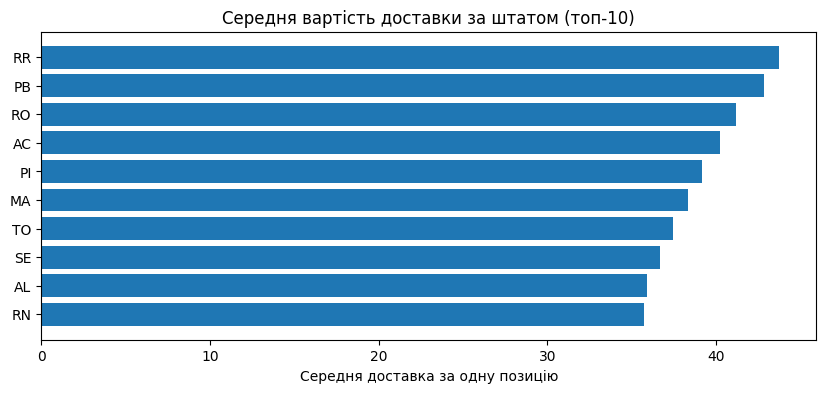

,avg_freight,freight_pct_of_price
customer_state,,
RR,43.70,28.70
PB,42.80,22.50
RO,41.20,24.60
AC,40.20,22.90
PI,39.20,24.30
MA,38.30,26.40
TO,37.40,23.70
SE,36.70,23.90
AL,35.90,19.80


In [49]:
freight = valid_items.groupby('customer_state').agg(
    avg_freight=('freight_value', 'mean'),
    freight=('freight_value', 'sum'),
    price=('price', 'sum'),
)
freight['freight_pct_of_price'] = freight['freight'] / freight['price'] * 100
freight = freight.sort_values('avg_freight', ascending=False)

plot_data = freight['avg_freight'].head(10).sort_values()
plt.barh(plot_data.index, plot_data.values)
plt.title('Середня вартість доставки за штатом (топ-10)')
plt.xlabel('Середня доставка за одну позицію')
plt.show()

freight[['avg_freight', 'freight_pct_of_price']].round(1).head(10)

**Мій висновок.**
- Найдорожча доставка в штатах **RR (43,7), PB (42,8), RO (41,2)**. Там доставка складає від 22% до 29% ціни товару.
- Штат **MA** є і в цьому топі (доставка 38,3, це 26,4% ціни), і лідером за часткою запізнень (17,4%). Я вважаю його найпроблемнішим регіоном: клієнт там платить більше й частіше чекає довше.

## 9. Повторні покупці

In [50]:
orders_per_customer = valid.groupby('customer_unique_id')['order_id'].count()

print('Скільки клієнтів зробили 1, 2, 3... замовлень:')
print(orders_per_customer.value_counts().sort_index())

repeat_pct = (orders_per_customer > 1).mean() * 100
print()
print('Частка повторних клієнтів, %:', round(repeat_pct, 2))

Скільки клієнтів зробили 1, 2, 3... замовлень:
order_id
1     92096
2      2651
3       188
4        29
5         9
6         5
7         3
9         1
16        1
Name: count, dtype: int64

Частка повторних клієнтів, %: 3.04


**Мій висновок.** Лише **3,04%** клієнтів зробили більше одного замовлення (2 651 клієнт купив двічі, 188 тричі), а **96,96%** купили лише раз. Тобто утримання клієнтів майже не працює. Для маркетплейсу це найбільша точка росту: навіть невелике збільшення повторних покупок збільшить виручку без витрат на залучення нових клієнтів.

## 10. Підсумки і рекомендації

| Питання | Результат |
|---|---|
| Ріст бізнесу | замовлень на місяць у 8 разів (2017-01 → 2018-08), пік у листопаді 2017 |
| Найбільші категорії | health_beauty, watches_gifts, bed_bath_table = 26,1% виручки |
| Географія | SP, RJ, MG = 66,5% замовлень |
| Доставка | в середньому 12,5 дня, запізнюється 6,8% замовлень |
| Затримка → оцінка | вчасно 4,29, із запізненням 2,27, понад 7 днів 1,70 |
| Проблемні штати | MA, CE, BA, RJ (12-17% запізнень) |
| Повторні покупці | лише 3,04% |

**Мої рекомендації:**
1. **Точність термінів важливіша за швидкість.** Оцінка падає від порушення обіцяної дати, тому в проблемних штатах (MA, CE, BA, RJ) варто реалістичніше розраховувати термін доставки.
2. **Працювати з утриманням клієнтів.** Лише 3% купують знову, тож варто розглянути програму лояльності та повторні комунікації після першої покупки.
3. **Розвивати інші регіони.** Дві третини замовлень зосереджені у трьох штатах.

**Обмеження аналізу.** У даних немає маркетингових витрат і маржі, оцінки є не для всіх замовлень, а зв'язок «затримка → оцінка» це кореляція. Наступний крок: зібрати ці результати в дашборд Power BI.